# Lab 02: Gaussian Naive Bayes — Customer Purchase Prediction

This laboratory project implements a probabilistic classification model using Gaussian Naive Bayes (`GaussianNB`) to predict customer purchase decisions based on behavioral metrics in an e-commerce platform.

### Objectives:
1. Ingest e-commerce customer interaction data.
2. Feature inspection, encoding, and exploratory visualization.
3. Stratified train/test splitting.
4. Model training with Gaussian Naive Bayes.
5. Evaluation across confusion matrix, accuracy, precision, and recall.
6. Sensitivity analysis across different test split ratios (10%, 20%, 30%).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load customer behavior dataset
df = pd.read_csv("data.csv")
print("Dataset Shape:", df.shape)
print("\nFirst 5 records:")
display(df.head())


Dataset Shape: (250, 15)

First 5 records:


,customer_id,gender,age,city,favorite_category,registration_date,total_orders,avg_order_value,days_since_last_purchase,visits_last_month,product_views,cart_adds,discount_used,is_loyalty_member,purchased
0,C1001,Female,18,Astana,Косметика,2024-10-01,7,13600,45,5,30,6,0,0,0
1,C1002,Male,19,Shymkent,Тұрмыстық техника,2023-04-02,4,20800,116,10,37,5,0,0,0
2,C1003,Male,39,Taraz,Clothing,2024-07-17,4,22500,42,3,13,1,0,0,0
3,C1004,Male,41,Атырау,Косметика,2025-03-09,4,13800,45,4,20,3,0,1,0
4,C1005,Male,34,Aktobe,Тұрмыстық техника,2025-08-16,3,11600,78,5,23,1,0,0,0


In [2]:
# Check target class distribution and null values
print("Target Class Distribution ('purchased'):")
print(df["purchased"].value_counts(normalize=True).round(3))
print("\nMissing values count:")
print(df.isnull().sum())


Target Class Distribution ('purchased'):
purchased
0    0.596
1    0.404
Name: proportion, dtype: float64

Missing values count:
customer_id                 0
gender                      0
age                         0
city                        0
favorite_category           0
registration_date           0
total_orders                0
avg_order_value             0
days_since_last_purchase    0
visits_last_month           0
product_views               0
cart_adds                   0
discount_used               0
is_loyalty_member           0
purchased                   0
dtype: int64


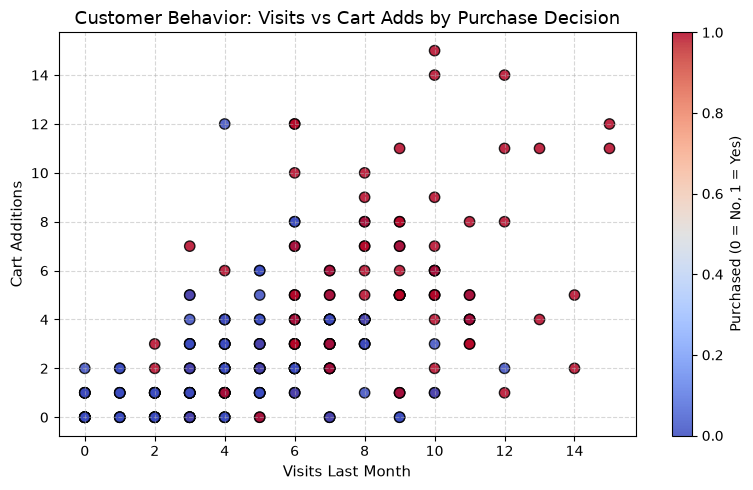

In [3]:
# Scatter visualization: visits vs cart additions colored by purchase status
plt.figure(figsize=(8, 5))
scatter = plt.scatter(df["visits_last_month"], df["cart_adds"], 
                      c=df["purchased"], cmap="coolwarm", alpha=0.85, edgecolors="k", s=55)
plt.xlabel("Visits Last Month", fontsize=11)
plt.ylabel("Cart Additions", fontsize=11)
plt.title("Customer Behavior: Visits vs Cart Adds by Purchase Decision", fontsize=13)
cbar = plt.colorbar(scatter)
cbar.set_label("Purchased (0 = No, 1 = Yes)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


In [4]:
# Feature encoding and selection
# Binary encode gender (Male: 1, Female/Other: 0)
df["gender_code"] = (df["gender"] == "Male").astype(int)

features = ["age", "gender_code", "total_orders", "avg_order_value", 
            "days_since_last_purchase", "visits_last_month", "cart_adds"]

X = df[features]
y = df["purchased"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Testing set:  {X_test.shape[0]} samples")


Training set: 200 samples
Testing set:  50 samples


In [5]:
# Train Gaussian Naive Bayes classifier
model = GaussianNB()
model.fit(X_train, y_train)

# Predict on test set
y_pred = model.predict(X_test)
acc = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {acc:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=["No Purchase", "Purchased"]))


Test Accuracy: 0.7600

Classification Report:
              precision    recall  f1-score   support

 No Purchase       0.80      0.80      0.80        30
   Purchased       0.70      0.70      0.70        20

    accuracy                           0.76        50
   macro avg       0.75      0.75      0.75        50
weighted avg       0.76      0.76      0.76        50



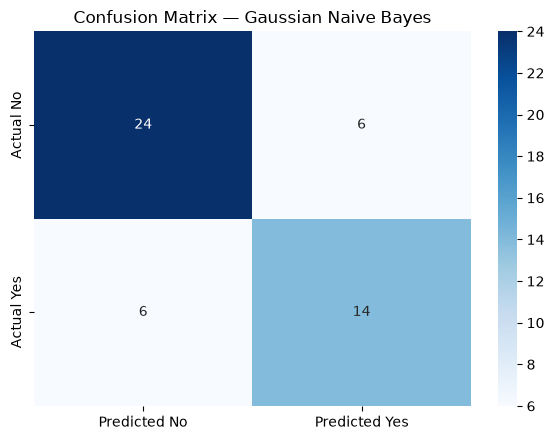

In [6]:
# Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", 
            xticklabels=["Predicted No", "Predicted Yes"],
            yticklabels=["Actual No", "Actual Yes"])
plt.title("Confusion Matrix — Gaussian Naive Bayes", fontsize=12)
plt.tight_layout()
plt.show()


In [7]:
# Sample inference: predicting for a new customer profile
# Profile: Age=34, Gender=Male(1), Orders=9, AvgCheck=25000, DaysSinceLast=15, Visits=12, CartAdds=4
new_customer = pd.DataFrame([[34, 1, 9, 25000, 15, 12, 4]], columns=features)
pred_class = model.predict(new_customer)[0]
pred_probs = model.predict_proba(new_customer)[0]

print(f"Predicted Class: {'Purchased (1)' if pred_class == 1 else 'No Purchase (0)'}")
print(f"Class Probabilities: P(No) = {pred_probs[0]:.3f}, P(Yes) = {pred_probs[1]:.3f}")


Predicted Class: Purchased (1)
Class Probabilities: P(No) = 0.082, P(Yes) = 0.918


In [8]:
# Sensitivity analysis across multiple test split ratios
split_ratios = [0.30, 0.20, 0.10]
print("Sensitivity Analysis across Split Ratios:")
for test_size in split_ratios:
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=test_size, random_state=42, stratify=y)
    m = GaussianNB()
    m.fit(X_tr, y_tr)
    preds = m.predict(X_te)
    score = accuracy_score(y_te, preds)
    print(f"  Test size {int(test_size*100)}% ({len(X_tr)} train / {len(X_te)} test) -> Accuracy: {score:.4f}")


Sensitivity Analysis across Split Ratios:
  Test size 30% (175 train / 75 test) -> Accuracy: 0.7200
  Test size 20% (200 train / 50 test) -> Accuracy: 0.7600
  Test size 10% (225 train / 25 test) -> Accuracy: 0.8000
